# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [43]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [44]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

Nazwy klas wzięte z https://huggingface.co/datasets/AI-MED-AGH/Recruitment-Task-2A

In [45]:
CLASS_NAMES = [
    "basophil",
    "eosinophil",
    "erythroblast",
    "immature gran.",
    "lymphocyte",
    "monocyte",
    "neutrophil",
    "platelet"
]

In [46]:
X_train, y_train = data["train_images"], data["train_labels"].ravel()
X_val, y_val = data["val_images"], data["val_labels"].ravel()
X_test, y_test = data["test_images"], data["test_labels"].ravel()

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name}: images {X.shape}, labels {y.shape}")
print("Total number of images: ", len(X_train) + len(X_val) + len(X_test))

print()
print("dtype:", X_train.dtype)
print("range:", X_train.min(), "-", X_train.max())

train: images (11959, 28, 28, 3), labels (11959,)
val: images (1712, 28, 28, 3), labels (1712,)
test: images (3421, 28, 28, 3), labels (3421,)
Total number of images:  17092

dtype: uint8
range: 0 - 255


                train  val  test
basophil          852  122   244
eosinophil       2181  312   624
erythroblast     1085  155   311
immature gran.   2026  290   579
lymphocyte        849  122   243
monocyte          993  143   284
neutrophil       2330  333   666
platelet         1643  235   470


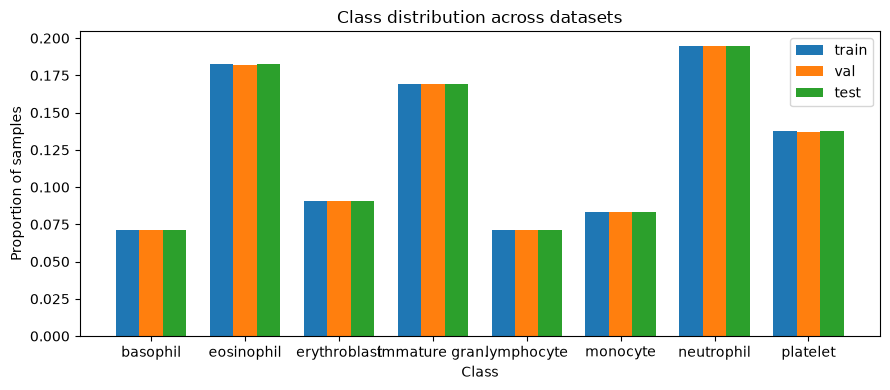

In [47]:
counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val": pd.Series(y_val).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index(),
})
counts.index = CLASS_NAMES
print(counts)


fig, ax = plt.subplots(figsize=(9, 4))
shares = counts.div(counts.sum(axis=0), axis=1)
x = np.arange(len(counts.index))
width = 0.25
for i, column in enumerate(shares.columns):
    ax.bar(x + (i - 1) * width, shares[column], width, label=column)

ax.set_xticks(x)
ax.set_xticklabels(counts.index)
ax.set_xlabel("Class")
ax.set_ylabel("Proportion of samples")
ax.set_title("Class distribution across datasets")
ax.legend()
plt.tight_layout()
plt.show()

In [48]:
import hashlib

def image_hashes(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

h_train = image_hashes(X_train)
h_val = image_hashes(X_val)
h_test = image_hashes(X_test)

print("duplicates inside train set:", len(h_train) - len(set(h_train)))

# checking if samples leaked from one set to another
print("train->val leak:", len(set(h_train) & set(h_val)))
print("train->test leak:", len(set(h_train) & set(h_test)))
print("val->test leak", len(set(h_val) & set(h_test)))

duplicates inside train set: 8
train->val leak: 3
train->test leak: 5
val->test leak 1


Kontrola wyżej pokazała niewielki wyciek. To mało w porównaniu z tym ile jest wszystkich obrazów, ale i tak je usunę.

In [49]:
set_val, set_test = set(h_val), set(h_test)

seen, keep_train = set(), []
for h in h_train:
    keep_train.append((h not in seen) and (h not in set_val) and (h not in set_test))
    seen.add(h)
keep_train = np.array(keep_train)
keep_val = np.array([h not in set_test for h in h_val])

X_train, y_train = X_train[keep_train], y_train[keep_train]
X_val, y_val = X_val[keep_val], y_val[keep_val]

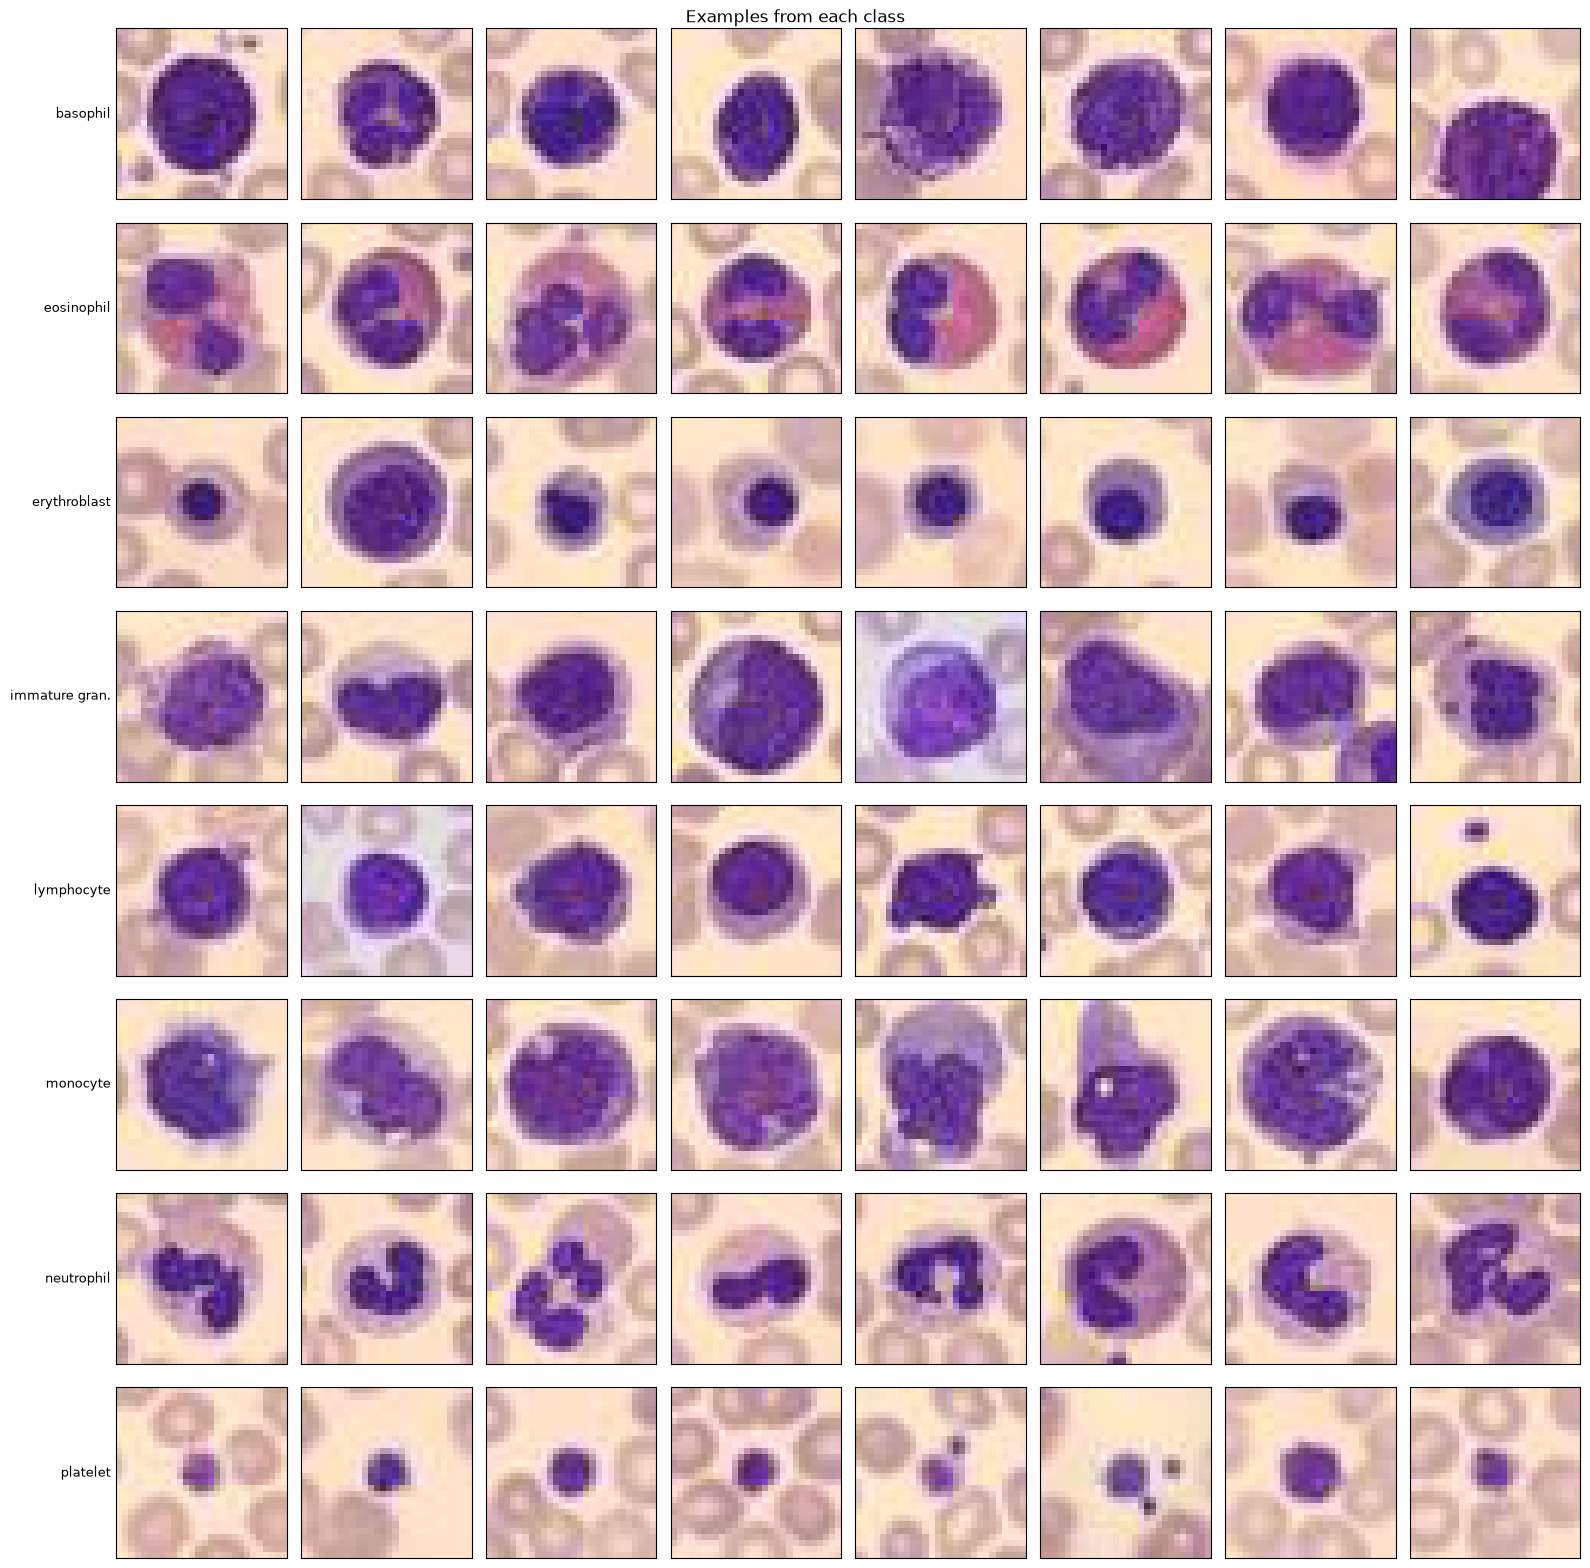

In [50]:
rng = np.random.default_rng(42)
n_per_class = 8
fig, axes = plt.subplots(8, n_per_class, figsize=(2 * n_per_class, 2 * 8))
for c in range(8):
    idx = rng.choice(np.where(y_train == c)[0], n_per_class, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i])
        axes[c, j].set_xticks([])
        axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Examples from each class")
plt.tight_layout()
plt.show()

## Wnioski po analizie danych

Obrazy mają mały rozmiar (28×28), kanał RGB i są wycentrowane, dlatego nie wymagają dodatkowego przycinania ani zmiany rozmiaru. Zbiór zawiera 8 klas o nierównych liczebnościach, dlatego rozważę wagi klas podczas treningu. Główną metryką oceny będzie macro F1, która traktuje wszystkie klasy jednakowo.

W modelach klasycznych zastosuję skalowanie pikseli do [0, 1] oraz feature engineering - dodanie cech opisujących kształt, kolor i teksturę komórek. Wykorzystam do tego m.in. rozciąganie kontrastu i ekstrakcję cech morfologicznych. Następnie zastosuję standaryzację danych. W sieciach neuronowych użyję dodatkowo normalizacji na podstawie średniej i odchylenia standardowego. Podczas treningu sieci zastosuję augmentację danych obejmującą odbicia, transpozycje oraz niewielkie zmiany jasności i kontrastu. Unikam silnych zmian kolorów, ponieważ mogą one zawierać istotne informacje diagnostyczne.

Modele, które przetestuję:
- dummyClassifier jako punkt odniesienia
- regresję logistyczną na surowych pikselach jako prosty model bazowy
- regresję logistyczną wykorzystującą ręcznie przygotowane cechy (morfologiczne, kolorystyczne i teksturalne)
- SVM z jądrem RBF, żeby sprawdzić, czy nieliniowość poprawi wyniki przy tych samych cechach
- LeNet-5, aby sprawdzić jak poradzi sobie sieć splotowa

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [51]:
import time

from joblib import Parallel, delayed
from scipy import ndimage as ndi
from skimage import color, exposure, filters, measure, morphology
from skimage.feature import local_binary_pattern
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [52]:
import io
import joblib

#function to calculate size of trained model
def model_size_kb(model) -> float:
    buf = io.BytesIO()
    joblib.dump(model, buf)
    return buf.getbuffer().nbytes / 1024

In [53]:
results = {}
fitted = {}


def fit_and_score(model, X_tr, X_va):
    start = time.perf_counter()
    model.fit(X_tr, y_train)
    fit_time = time.perf_counter() - start
    pred = model.predict(X_va)
    return {
        "val_acc": accuracy_score(y_val, pred),
        "val_bal_acc": balanced_accuracy_score(y_val, pred),
        "val_f1_macro": f1_score(y_val, pred, average="macro"),
        "fit_time_s": fit_time,
        "size_kb": model_size_kb(model),
    }

def register(name, model, row, kind, params=None):
    results[name] = {**row, "parameters": params(model) if params else None}
    fitted[name] = (model, kind)

In [54]:
def get_model_from_pipeline(p):
    return p.named_steps["clf"] if hasattr(p, "named_steps") else p

def logreg_params(p):
    clf = get_model_from_pipeline(p)
    return clf.coef_.size + clf.intercept_.size

def svm_params(p):
    clf = get_model_from_pipeline(p)
    return clf.support_vectors_.size + clf.dual_coef_.size + clf.intercept_.size

## Baseline i regresja logistyczna na surowych pikselach

In [55]:
X_train_flat = X_train.reshape(len(X_train), -1).astype(np.float32) / 255
X_val_flat = X_val.reshape(len(X_val), -1).astype(np.float32) / 255
X_test_flat = X_test.reshape(len(X_test), -1).astype(np.float32) / 255

dummy = DummyClassifier(strategy="most_frequent")
register("dummy", dummy, fit_and_score(dummy, X_train_flat, X_val_flat), "raw")

logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l2", C=1.0, max_iter=2000))
])
register("logreg", logreg_pipeline, fit_and_score(logreg_pipeline, X_train_flat, X_val_flat), "raw", logreg_params)

e:\Programowanie\Python projects\Rekrutacja-AI-Med-2026-2027\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [56]:
pd.DataFrame(results).T.round(4)

,val_acc,val_bal_acc,val_f1_macro,fit_time_s,size_kb,parameters
dummy,0.1946,0.1250,0.0407,0.0007,0.6162,NaN
logreg,0.8054,0.7771,0.7762,19.5337,129.9932,18824.0


Dummy osiąga około 0,19 accuracy, czyli tyle, ile wynosi udział najliczniejszej klasy w zbiorze walidacyjnym, a macro F1 bliskie zeru. Pokazuje to, że przy nierównych klasach sama accuracy może wprowadzać w błąd.

## Feature engineering: kontrast, morfologia matematyczna, kolor, tekstura

Typy komórek różnią się przede wszystkim wielkością, kształtem oraz wyglądem jądra i barwą. Dlatego zdecydowałem się opisać obrazy za pomocą cech związanych z tymi właściwościami. Na początku poprawiam kontrast obrazu, rozciągając wartości każdego kanału kolorów między 2 a 98 percentylem. Dzięki temu ograniczam różnice w oświetleniu. Następnie wyznaczam maskę komórki i jej jądra. Wykorzystuję do tego progowanie otsu, które automatycznie dobiera próg jasności lub nasycenia, pozwalający oddzielić interesujący obiekt od tła. Uzyskane maski oczyszczam z drobnych zakłóceń i wypełniam ewentualne dziury. Na podstawie masek wyznaczam cechy opisujące kształt i wielkość komórki oraz jądra, między innymi ich pole, obwód, wydłużenie i stosunek powierzchni jądra do powierzchni komórki. Dodatkowo wykorzystuję podstawowe statystyki kolorów, takie jak średnia i odchylenie standardowe kanałów RGB i HSV, zarówno dla całego obrazu, jak i wykrytych obszarów.

In [57]:
def stretch_contrast(img):
    out = np.zeros(img.shape, dtype=float)

    for c in range(3):
        lo, hi = np.percentile(img[..., c], (2, 98))
        out[..., c] = exposure.rescale_intensity(
            img[..., c].astype(float),
            in_range=(lo, hi + 1e-6),
            out_range=(0, 1)
        )

    return out


def largest_component(mask):
    labels, n = ndi.label(mask)

    if n == 0:
        return mask

    sizes = ndi.sum(mask, labels, index=range(1, n + 1))
    return labels == (np.argmax(sizes) + 1)


def cell_mask(saturation):
    threshold = filters.threshold_otsu(saturation)
    mask = saturation > threshold

    mask = morphology.opening(mask, morphology.disk(1))
    mask = morphology.closing(mask, morphology.disk(1))
    mask = ndi.binary_fill_holes(mask)

    return largest_component(mask)


def nucleus_mask(green, cell):
    if cell.sum() < 5:
        return np.zeros_like(cell, dtype=bool)

    threshold = filters.threshold_otsu(green[cell])
    mask = cell & (green < threshold)

    return morphology.opening(mask, morphology.disk(1))


def extract_features(img):
    features = {}

    rgb = stretch_contrast(img)
    hsv = color.rgb2hsv(rgb)

    for i, channel in enumerate("RGB"):
        features[f"mean_{channel}"] = rgb[..., i].mean()
        features[f"std_{channel}"] = rgb[..., i].std()

    for i, channel in enumerate("HSV"):
        features[f"mean_{channel}"] = hsv[..., i].mean()
        features[f"std_{channel}"] = hsv[..., i].std()

    cell = cell_mask(hsv[..., 1])
    nucleus = nucleus_mask(rgb[..., 1], cell)

    for name, mask in [("cell", cell), ("nuc", nucleus)]:

        features[f"{name}_area"] = mask.mean()

        labels = measure.label(mask)
        regions = measure.regionprops(labels)

        if regions:
            region = max(regions, key=lambda r: r.area)

            features[f"{name}_perimeter"] = region.perimeter
            features[f"{name}_eccentricity"] = region.eccentricity
            features[f"{name}_major_axis"] = region.axis_major_length
            features[f"{name}_minor_axis"] = region.axis_minor_length
        else:
            for feature in ["perimeter", "eccentricity",
                        "major_axis", "minor_axis"]:
                features[f"{name}_{feature}"] = 0.0

        for i, channel in enumerate("RGB"):
            features[f"{name}_mean_{channel}"] = (
                rgb[..., i][mask].mean() if mask.any() else 0.0
            )

    features["nuc_to_cell_area"] = (
        nucleus.sum() / max(cell.sum(), 1)
    )

    return features

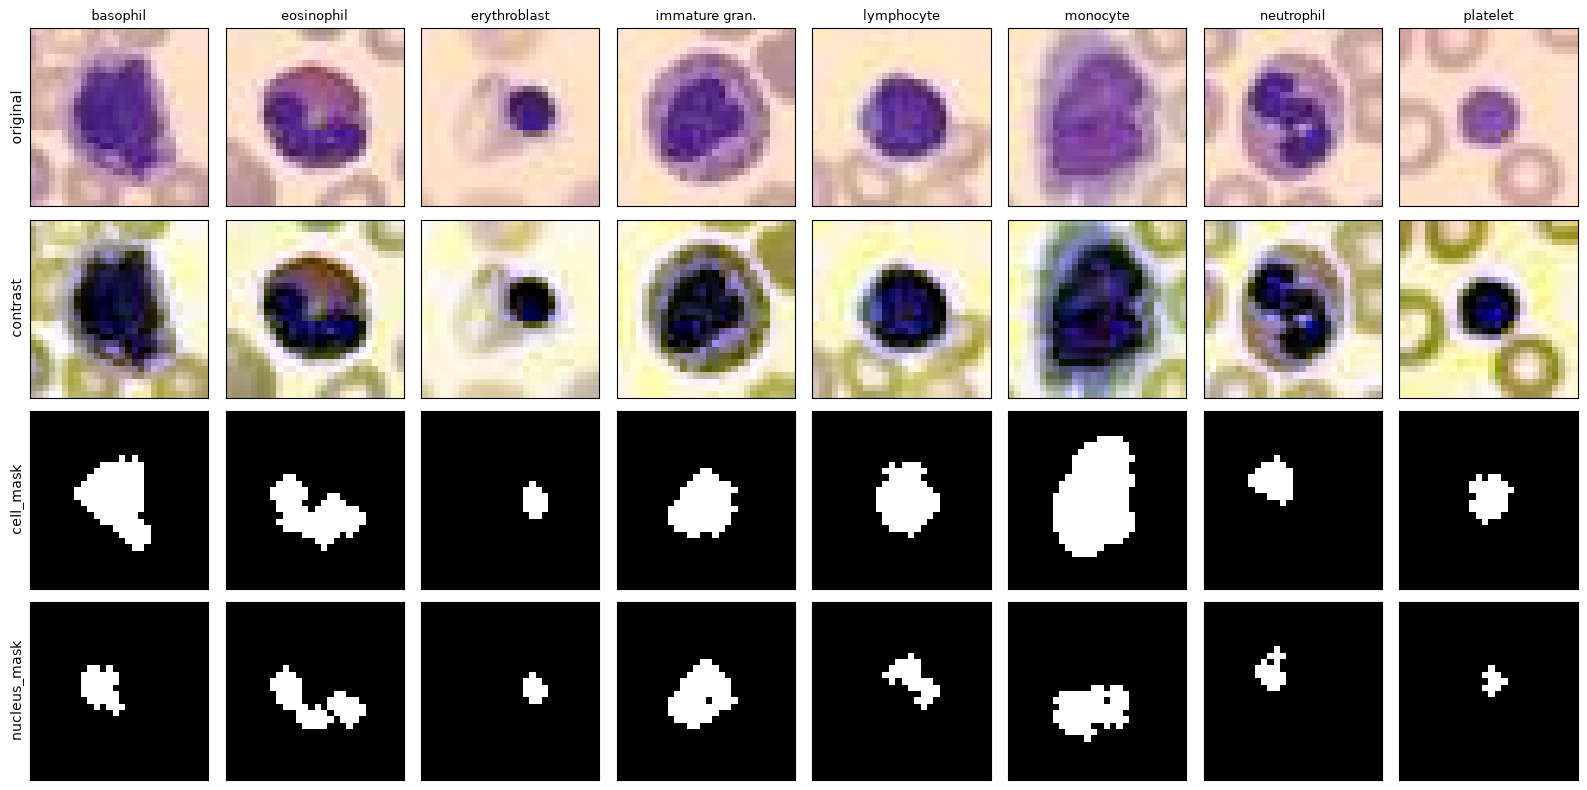

In [58]:
rng = np.random.default_rng(42)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for c in range(8):
    img = X_train[rng.choice(np.where(y_train == c)[0])]
    rgb = stretch_contrast(img)
    cell = cell_mask(color.rgb2hsv(rgb)[..., 1])
    nuc = nucleus_mask(rgb[..., 1], cell)
    for r, (im, cmap) in enumerate([(img, None), (rgb, None), (cell, "gray"), (nuc, "gray")]):
        axes[r, c].imshow(im, cmap=cmap)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=9)
for r, label in enumerate(["original", "contrast", "cell_mask", "nucleus_mask"]):
    axes[r, 0].set_ylabel(label)
plt.tight_layout()
plt.show()

In [59]:
def extract_all(X):
    rows = Parallel(n_jobs=-1)(delayed(extract_features)(img) for img in X)
    return pd.DataFrame(rows)

start = time.perf_counter()
final_train = extract_all(X_train)
final_val = extract_all(X_val)
final_test = extract_all(X_test)

In [60]:
logreg_pipeline_improved = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l2", C=1, max_iter=2000))
])
register("logreg_features", logreg_pipeline_improved, fit_and_score(logreg_pipeline_improved, final_train, final_val), "raw", logreg_params)

e:\Programowanie\Python projects\Rekrutacja-AI-Med-2026-2027\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [61]:
pd.DataFrame(results).T.round(4)

,val_acc,val_bal_acc,val_f1_macro,fit_time_s,size_kb,parameters
dummy,0.1946,0.1250,0.0407,0.0007,0.6162,NaN
logreg,0.8054,0.7771,0.7762,19.5337,129.9932,18824.0
logreg_features,0.8539,0.8207,0.8255,0.5622,4.4150,240.0


In [62]:
svm_pipeline_improved = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf"))
])
register("svm_features", svm_pipeline_improved, fit_and_score(svm_pipeline_improved, final_train, final_val), "raw", svm_params)

In [63]:
pd.DataFrame(results).T.round(4)

,val_acc,val_bal_acc,val_f1_macro,fit_time_s,size_kb,parameters
dummy,0.1946,0.1250,0.0407,0.0007,0.6162,NaN
logreg,0.8054,0.7771,0.7762,19.5337,129.9932,18824.0
logreg_features,0.8539,0.8207,0.8255,0.5622,4.4150,240.0
svm_features,0.8714,0.8392,0.8455,1.7932,1661.1182,175564.0


### Hiperparametry dla modeli ML

In [64]:
import optuna
from sklearn.model_selection import cross_val_score
import time

optuna.logging.set_verbosity(optuna.logging.WARNING)

def build_model(name, trial):
    if name == "logreg":
        clf = LogisticRegression(C=trial.suggest_float("C", 1e-2, 1e3, log=True), max_iter=2000)
    else:  # svm
        clf = SVC(
            C=trial.suggest_float("C", 0.1, 1e3, log=True),
            gamma=trial.suggest_float("gamma", 1e-3, 10, log=True),
        )

    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", clf),
    ])

n_trials = {"logreg": 30, "svm": 30}
tuned, tuned_fit_time = {}, {}

for name in ["logreg", "svm"]:
    def objective(trial):
        scores = cross_val_score(build_model(name, trial), final_train, y_train,
                                 cv=5, scoring="accuracy", n_jobs=-1)
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials[name])

    best = build_model(name, optuna.trial.FixedTrial(study.best_params))
    register(name + "_tuned", best, fit_and_score(best, final_train, final_val), "tuned", logreg_params if name == "logreg" else svm_params)

    print(f"{name}: cv_acc = {study.best_value:.4f}")
    print("--]", study.best_params)

logreg: cv_acc = 0.8708
--] {'C': 351.4601644783772}
svm: cv_acc = 0.9071
--] {'C': 925.8391486478649, 'gamma': 0.004144064974418403}


In [65]:
pd.DataFrame(results).T.round(4)

,val_acc,val_bal_acc,val_f1_macro,fit_time_s,size_kb,parameters
dummy,0.1946,0.1250,0.0407,0.0007,0.6162,NaN
logreg,0.8054,0.7771,0.7762,19.5337,129.9932,18824.0
logreg_features,0.8539,0.8207,0.8255,0.5622,4.4150,240.0
svm_features,0.8714,0.8392,0.8455,1.7932,1661.1182,175564.0
logreg_tuned,0.8743,0.8524,0.8547,1.9186,4.4307,240.0
svm_tuned,0.9071,0.8931,0.8948,2.7427,1021.1807,107776.0


Ręczne cechy wyraźnie poprawiły regresję logistyczną, a dzięki dostrajaniu hiperparametrów model ma tylko 240 parametrów zamiast 18 tysięcy, więc jest też mniejszy i uczy się szybciej. SVM z jądrem RBF poprawił wynik o około 3 punkt procentowe, czyli nieliniowość nadal pomaga, ale niewiele, za to model jest zdecydowanie większy.

## Sieci splotowe

Żeby pokazać, że sieci konwolucyjne mogą być lepsze od klasycznego ML, trenuję LeNet-5. Jest to mała sensowna sieć konwolucyjna (około 45 tysięcy parametrów) i szybko się trenuje. Trenuję ją według standardowej procedury. Funkcją kosztu jest CrossEntropyLoss, standardowa dla klasyfikacji wieloklasowej. Optymalizatorem jest AdamW, a współczynnik uczenia zmniejszam, gdy strata przestaje spadać. Po każdej epoce liczę macro F1 na zbiorze walidacyjnym, zatrzymuję trening, gdy przez osiem epok nie ma poprawy, i wracam do wag z najlepszej epoki, dzięki czemu walidacja służy jednocześnie do wyboru modelu i wczesnego zatrzymania. Augmentację wykonuję wyłącznie na zbiorze treningowym, ponieważ poprawia ona generalizację modelu.

In [68]:
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

def to_tensor(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).float() / 255

Xtr = to_tensor(X_train)
Xva = to_tensor(X_val)
Xte = to_tensor(X_test)
ytr = torch.tensor(y_train, dtype=torch.long)

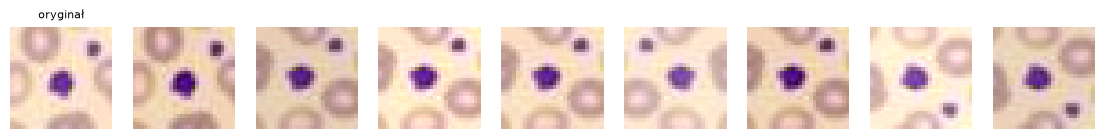

In [ ]:
def augment(x):
    b = x.size(0)

    if torch.rand(b, 1, 1, 1, device=x.device).lt(0.5).any():
        x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)

    x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.flip(2), x)
    x = torch.where(torch.rand(b, 1, 1, 1, device=x.device) < 0.5, x.transpose(2, 3), x)

    mean = x.mean((1, 2, 3), keepdim=True)
    contrast = 1 + 0.15 * (torch.rand(b, 1, 1, 1, device=x.device) * 2 - 1)
    brightness = 0.08 * (torch.rand(b, 1, 1, 1, device=x.device) * 2 - 1)

    return ((x - mean) * contrast + mean + brightness).clamp(0, 1)

# augmentation view
sample = Xtr[:1].repeat(8, 1, 1, 1)
aug = augment(sample)
fig, axes = plt.subplots(1, 9, figsize=(14, 1.9))
axes[0].imshow(Xtr[0].permute(1, 2, 0).cpu())
axes[0].set_title("orginal", fontsize=8)
for i in range(8):
    axes[i + 1].imshow(aug[i].permute(1, 2, 0))
for a in axes:
    a.axis("off")
plt.show()

In [78]:
MEAN = Xtr.mean((0, 2, 3), keepdim=True)
STD = Xtr.std((0, 2, 3), keepdim=True)

class LeNet5(nn.Module):
    def __init__(self, n_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 6, 5),
            nn.Tanh(),
            nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5),
            nn.Tanh()
        )

        self.head = nn.Sequential(
            nn.AvgPool2d(2),
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, n_classes)
        )

    def forward(self, x):
        x = (x - MEAN.to(x.device)) / STD.to(x.device)
        return self.head(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


print("LeNet5:", count_params(LeNet5()), "parameters")

LeNet5: 44556 parameters


In [82]:
import torch.nn.functional as F
import copy

@torch.no_grad()
def predict_proba(model, X, batch_size=1024):
    model.eval()
    return torch.cat([
        F.softmax(model(X[i:i+batch_size]), dim=1)
        for i in range(0, len(X), batch_size)
    ]).numpy()


fitted_cnn, histories = {}, {}

def train_model(model, name, epochs=40, lr=1e-3, weight_decay=1e-4,
                use_aug=False, patience=8, batch_size=128):

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    criterion = nn.CrossEntropyLoss()

    history = []
    best_f1, best_state, wait = -1, None, 0
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr))
        total_loss = 0

        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i+batch_size]
            xb, yb = Xtr[idx], ytr[idx]

            if use_aug:
                xb = augment(xb)

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(idx)

        probs = predict_proba(model, Xva)
        pred = probs.argmax(axis=1)
        val_loss = -np.log(probs[np.arange(len(y_val)), y_val] + 1e-12).mean()
        val_f1 = f1_score(y_val, pred, average="macro")

        scheduler.step(val_loss)

        history.append({
            "epoch": epoch,
            "train_loss": total_loss / len(Xtr),
            "val_loss": val_loss,
            "val_acc": (pred == y_val).mean(),
            "val_f1": val_f1
        })

        if val_f1 > best_f1 + 1e-4:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)
    pred = predict_proba(model, Xva).argmax(axis=1)

    results[name] = {
        "val_acc": accuracy_score(y_val, pred),
        "val_bal_acc": balanced_accuracy_score(y_val, pred),
        "val_f1_macro": f1_score(y_val, pred, average="macro"),
        "fit_time_s": time.perf_counter() - start,
        "parameters": count_params(model),
        "size_kb": model_size_kb(model),
        "epochs_run": len(history)
    }

    fitted_cnn[name] = model
    histories[name] = pd.DataFrame(history)

    return model


def plot_history(name):
    h = histories[name]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))

    ax[0].plot(h.epoch, h.train_loss, label="train")
    ax[0].plot(h.epoch, h.val_loss, label="val")
    ax[0].set_title("Loss")
    ax[0].legend()

    ax[1].plot(h.epoch, h.val_f1, label="macro F1")
    ax[1].plot(h.epoch, h.val_acc, label="accuracy")
    ax[1].axvline(h.loc[h.val_f1.idxmax(), "epoch"], linestyle="--", color="gray")
    ax[1].set_title("Validation performance")
    ax[1].legend()

    plt.tight_layout()
    plt.show()

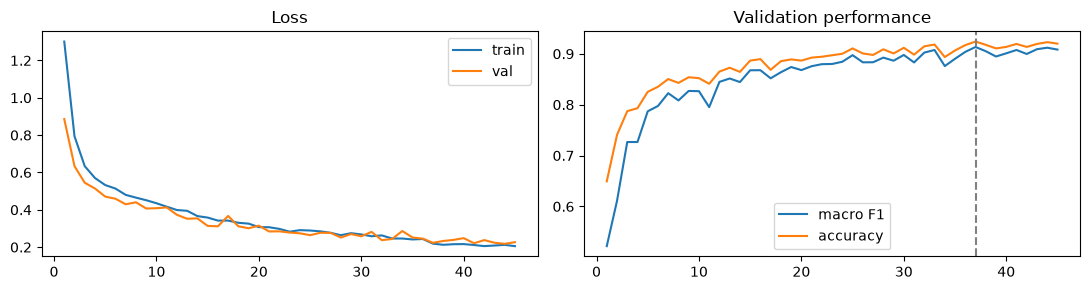

,val_acc,val_bal_acc,val_f1_macro,fit_time_s,size_kb,parameters,epochs_run
dummy,0.1946,0.1250,0.0407,0.0007,0.6162,NaN,NaN
logreg,0.8054,0.7771,0.7762,19.5337,129.9932,18824.0,NaN
logreg_features,0.8539,0.8207,0.8255,0.5622,4.4150,240.0,NaN
svm_features,0.8714,0.8392,0.8455,1.7932,1661.1182,175564.0,NaN
logreg_tuned,0.8743,0.8524,0.8547,1.9186,4.4307,240.0,NaN
svm_tuned,0.9071,0.8931,0.8948,2.7427,1021.1807,107776.0,NaN
lenet5_aug,0.9240,0.9126,0.9134,37.4537,179.8652,44556.0,45.0


In [83]:
train_model(LeNet5(), "lenet5_aug", epochs=60, use_aug=True)
plot_history("lenet5_aug")
pd.DataFrame(results).T.round(4)

Model LeNet-5 uzyskał lepsze rezultaty na zbiorze walidacyjnym niż tradycyjne metody, takie jak SVM czy regresja logistyczna, ponieważ sieć samodzielnie wyodrębnia cechy bezpośrednio z pikseli obrazu, eliminując konieczność ręcznego ich definiowania oraz przeprowadzania segmentacji, która stanowiła istotne ograniczenie wcześniejszych podejść. Model charakteryzuje się stosunkowo niewielką złożonością, jednak jego trenowanie wymaga więcej czasu niż w przypadku klasycznych algorytmów. Osiągnięte wyniki mogłyby być jeszcze lepsze, ponieważ proces uczenia zakończono po osiągnięciu wcześniej określonej liczby epok.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [91]:
test_preds = {}
test_preds["dummy"] = fitted["dummy"][0].predict(X_test_flat)
test_preds["logreg"] = fitted["logreg"][0].predict(X_test_flat)
test_preds["logreg_features"] = fitted["logreg_features"][0].predict(final_test)
test_preds["svm_features"] = fitted["svm_features"][0].predict(final_test)
test_preds["lenet5_aug"] = predict_proba(fitted_cnn["lenet5_aug"], Xte).argmax(axis=1)

best_name = max(test_preds, key=lambda n: results[n]["val_f1_macro"])
print("Best model:", best_name)

test_results = pd.DataFrame({
    name: {
        "test_acc": accuracy_score(y_test, pred),
        "test_bal_acc": balanced_accuracy_score(y_test, pred),
        "test_f1_macro": f1_score(y_test, pred, average="macro"),
        "val_f1_macro": results[name]["val_f1_macro"],
    }
    for name, pred in test_preds.items()
}).T.round(4)

test_results

Best model: lenet5_aug


,test_acc,test_bal_acc,test_f1_macro,val_f1_macro
dummy,0.1947,0.1250,0.0407,0.0407
logreg,0.7881,0.7674,0.7637,0.7762
logreg_features,0.8477,0.8112,0.8183,0.8255
svm_features,0.8661,0.8337,0.8410,0.8455
lenet5_aug,0.9103,0.8926,0.8984,0.9134


                precision    recall  f1-score   support

      basophil     0.8628    0.7992    0.8298       244
    eosinophil     0.9871    0.9776    0.9823       624
  erythroblast     0.9502    0.9196    0.9346       311
immature gran.     0.7582    0.8394    0.7967       579
    lymphocyte     0.9129    0.9053    0.9091       243
      monocyte     0.8256    0.7500    0.7860       284
    neutrophil     0.9622    0.9565    0.9593       666
      platelet     0.9852    0.9936    0.9894       470

      accuracy                         0.9103      3421
     macro avg     0.9055    0.8926    0.8984      3421
  weighted avg     0.9123    0.9103    0.9107      3421



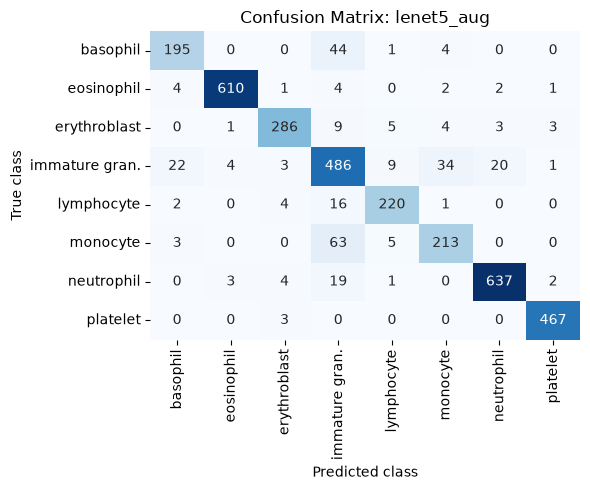

Most common errors:
monocyte -> immature gran.: 63
basophil -> immature gran.: 44
immature gran. -> monocyte: 34


In [93]:
y_pred_best = test_preds[best_name]

print(classification_report(y_test, y_pred_best, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.show()

errors = sorted(
    [(cm[i, j], i, j) for i in range(8) for j in range(8) if i != j],
    reverse=True
)[:3]

print("Most common errors:")
for count, true, pred in errors:
    print(f"{CLASS_NAMES[true]} -> {CLASS_NAMES[pred]}: {count}")

In [94]:
def grad_cam(model, x, target=None):
    model.eval()
    A = model.features(x)
    A.retain_grad()
    logits = model.head(A)
    cls = logits.argmax(dim=1).item() if target is None else target
    model.zero_grad()
    logits[0, cls].backward()
    weights = A.grad.mean(dim=(2, 3), keepdim=True)
    
    cam = F.relu((weights * A).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    probs = F.softmax(logits, dim=1)[0]

    return cam.detach().cpu().numpy(), probs.detach().cpu().numpy()

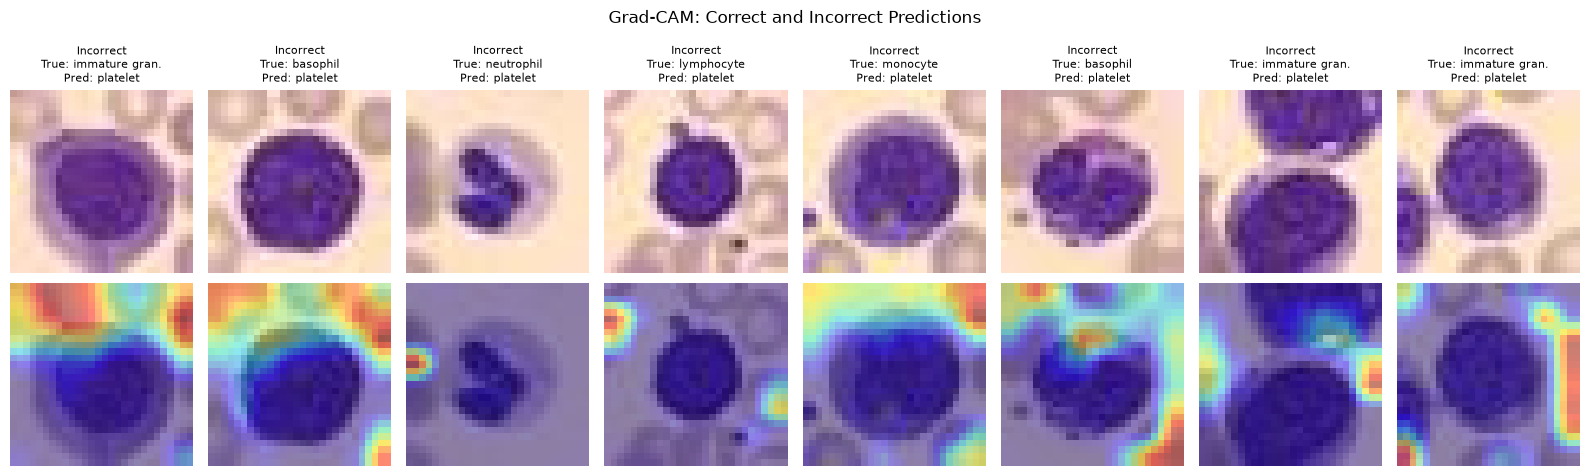

In [96]:
cnn = fitted_cnn["lenet5_aug"]
y_pred_cnn = test_preds["lenet5_aug"]
rng = np.random.default_rng(42)

ok_idx = [rng.choice(np.where((y_test == c) & (y_pred_cnn == c))[0]) for c in rng.choice(8, 4, replace=False)]

cm = confusion_matrix(y_test, y_pred_cnn)
top_pairs = sorted(
    [(cm[i, j], i, j) for i in range(8) for j in range(8) if i != j and cm[i, j] > 0], reverse=True
)[:4]

bad_idx = [rng.choice(np.where((y_test == i) & (y_pred_cnn == j))[0]) for _, i, j in top_pairs]

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for col, idx in enumerate(list(ok_idx) + list(bad_idx)):
    cam, probs = grad_cam(cnn, Xte[idx:idx+1])
    img = Xte[idx].permute(1, 2, 0).numpy()

    pred = probs.argmax()
    true = y_test[idx]

    axes[0, col].imshow(img)
    axes[0, col].set_title(
        f"{'Correct' if pred == true else 'Incorrect'}\n"
        f"True: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]}",
        fontsize=8
    )
    axes[1, col].imshow(img)
    axes[1, col].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Grad-CAM: Correct and Incorrect Predictions")
plt.tight_layout()
plt.show()

Analiza map Grad-CAM pokazuje, że sieć nie zawsze koncentruje się na najważniejszych cechach komórki. W części przykładów duże znaczenie mają również fragmenty tła i krawędzie obrazu, co może świadczyć o wykorzystywaniu przez model przypadkowych zależności występujących w danych. Warto również zauważyć, że wszystkie przedstawione błędne predykcje zostały przypisane do klasy platelet, mimo że należą do różnych klas rzeczywistych. Może to sugerować, że model nauczył się cech wspólnych, które błędnie interpretuje jako charakterystyczne. Wyniki wskazują, że wysoka skuteczność klasyfikacji nie oznacza, że model zawsze podejmuje decyzje na podstawie właściwych cech.

## Podsumowanie

Najlepsze wyniki uzyskał LeNet-5 z augmentacją danych, który przewyższył wszystkie przetestowane modele klasyczne. Sieć uczy się cech bezpośrednio z obrazów, bez konieczności ręcznego projektowania cech i segmentacji. Eksperyment pokazał, że metody oparte na feature engineering są skuteczniejsze od klasyfikacji na surowych pikselach, ale sieć neuronowa pozwala uzyskać jeszcze lepsze rezultaty. Jej wadą jest dłuższy czas treningu w porównaniu z klasycznymi algorytmami. Ogólnie przewaga CNN jest zauważalna (i może być lepsza używając lepszych modeli np LetNet PLus). Analiza pomyłek pozwala wskazać klasy, które są najtrudniejsze do rozróżnienia. Część błędów może wynikać z podobieństwa komórek, co jest jak najbardziej możliwe w tego typu problemie.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

Żródła:
- Aurelien Geron "Uczenie maszynowe z użyciem Scikit-Learn i TensorFlow"
- 
- https://claude.ai